# An A/B Test End-to-End: Design, SRM, Analysis, Decision

**What you'll learn**

- How to write the *design doc* before touching data: hypothesis, primary metric (and why
  binary conversion usually beats revenue-per-user on variance grounds), unit of
  randomization, guardrails, MDE → sample size → duration.
- Deterministic hash-based assignment: why production platforms use it, how to verify
  balance and cross-experiment independence, and why `hash()` in Python would silently
  destroy reproducibility.
- Sample-ratio mismatch (SRM): the single most important pre-analysis check. We break the
  bucketing pipeline on purpose, watch a chi-square test catch it, and quantify exactly how
  biased the "results" would have been had we analyzed anyway.
- The full readout: two-proportion z-test with CIs in absolute *and* relative lift, Welch +
  bootstrap for heavy-tailed revenue, and a per-metric experiment scorecard like a real
  platform renders.
- Segment discipline: pre-registered cuts with interaction tests vs post-hoc fishing, and
  what multiple-testing correction does to the "Safari-on-Tuesday" finding.
- A decision framework that separates statistical significance, practical significance, and
  guardrails — plus novelty/primacy effects and the senior experiment-review checklist.

**Why it matters in interviews**

- "Walk me through designing an experiment for feature X" is *the* canonical senior DS/AS
  interview question. The strong answer is a structured pipeline, not a list of tests.
- "What is SRM and what do you do about it?" separates people who have run real experiments
  from people who have read about them.
- "Conversion is up but revenue is flat — do we ship?" tests whether you understand power,
  metric hierarchies, and absence-of-evidence vs evidence-of-absence.
- Experiment-review rounds probe segment fishing, peeking, and practical-vs-statistical
  significance — all demonstrated here with known ground truth.

We simulate the data so the true effect is *known* (+0.2pp on conversion) and every method
can be checked against it. Deep dives live in siblings: power/MDE by simulation in
[02_power_mde_sample_size.ipynb](./02_power_mde_sample_size.ipynb), variance reduction in
[03_variance_reduction_cuped.ipynb](./03_variance_reduction_cuped.ipynb), sequential
monitoring in [04_peeking_sequential.ipynb](./04_peeking_sequential.ipynb), ratio metrics in
[05_ratio_metrics_delta_method.ipynb](./05_ratio_metrics_delta_method.ipynb), and the
testing machinery itself in
[../01_statistical_foundations/02_hypothesis_testing_beyond_basics.ipynb](../01_statistical_foundations/02_hypothesis_testing_beyond_basics.ipynb).

In [1]:
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8.0, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)

Z975 = stats.norm.ppf(0.975)  # 1.95996...

## 1. The scenario and the design doc

You are the data scientist on a checkout-flow experiment at an e-commerce company. The
checkout team rebuilt the payment step (fewer form fields, saved payment methods surfaced
earlier). The PM wants to launch; your job is to design the test.

**Everything below gets written down *before* launch.** A design doc you can't be graded
against is not a design doc.

- **Hypothesis.** Reducing friction at the payment step increases the probability that a
  user who reaches checkout completes a purchase. Mechanism: fewer abandoned payments.
- **Population / trigger.** Users who *reach checkout*. Randomizing all site visitors would
  dilute the effect with users who never see the change (Pitfall 2 quantifies this).
- **Unit of randomization.** The **user** (hashed persistent ID), not the session or
  pageview. Users must get a consistent experience across visits, and outcomes within a
  user are correlated — session-level randomization breaks the independence assumption of
  every test below (clustered/ratio-metric analysis is
  [05_ratio_metrics_delta_method.ipynb](./05_ratio_metrics_delta_method.ipynb)'s topic).
- **Candidate primary metrics.** Checkout conversion (binary, per user) vs revenue per user
  (continuous, zero-inflated, heavy-tailed). We choose with a variance argument, below.
- **Guardrails.** Checkout latency (the redesign adds JS), support-contact rate, refund
  rate among purchasers. Guardrails get *non-inferiority margins*, not significance hunts.

First, the design inputs. In real life you pull last quarter's logs; here we simulate the
platform's data-generating process (so ground truth is known) and draw a "historical" week
from it. Baseline checkout conversion is about 3%, and revenue is zero for ~97% of users
with a heavy-tailed spend distribution among converters — both typical of e-commerce.

In [2]:
# ---- The platform's data-generating process (ground truth known to us, not to the "DS") ----
TRUE_EFFECT_PP = 0.002        # +0.2pp absolute on checkout conversion, uniform across users
DAILY_LAMBDA = np.array([16_500, 16_000, 16_000, 16_500, 17_500, 19_500, 17_000])  # Mon..Sun
DOW_MULT     = np.array([1.00, 0.98, 0.97, 0.99, 1.03, 1.06, 0.97])   # conversion seasonality
BASE_RATE = {  # baseline conversion by (device, user_type)
    ("mobile", "new"): 0.0210, ("mobile", "returning"): 0.0315,
    ("desktop", "new"): 0.0335, ("desktop", "returning"): 0.0435,
}
SPEND_MU, SPEND_SIGMA = 3.662, 1.2   # lognormal spend | converted: mean ~ $80, heavy tail


def simulate_population(n_days, rng, uid_prefix="u"):
    """Users reaching checkout over `n_days`, with covariates and baseline conversion prob."""
    n_per_day = rng.poisson(DAILY_LAMBDA[np.arange(n_days) % 7])
    day = np.repeat(np.arange(n_days), n_per_day)
    n = day.size
    df = pd.DataFrame({
        "uid": [f"{uid_prefix}{i:07d}" for i in range(n)],
        "day": day,
        "dow": day % 7,
        "device": rng.choice(["mobile", "desktop"], size=n, p=[0.62, 0.38]),
        "user_type": rng.choice(["new", "returning"], size=n, p=[0.45, 0.55]),
        "browser": rng.choice(["chrome", "safari", "firefox", "edge", "other"],
                              size=n, p=[0.48, 0.27, 0.10, 0.09, 0.06]),
        "app_build": rng.choice(["current", "legacy"], size=n, p=[0.90, 0.10]),
    })
    cell = df.set_index(["device", "user_type"]).index.map(BASE_RATE).to_numpy()
    build_mult = np.where(df["app_build"] == "legacy", 0.6, 1.0)  # old builds convert worse
    df["p_base"] = cell * DOW_MULT[df["dow"]] * build_mult
    return df


def realize_outcomes(df, treated, effect_pp, rng):
    """Draw conversion, spend, and guardrail metrics given a treatment assignment."""
    out = df.copy()
    out["treated"] = treated
    p = np.clip(out["p_base"].to_numpy() + effect_pp * treated, 0, 1)
    conv = rng.random(len(out)) < p
    spend = np.zeros(len(out))
    spend[conv] = rng.lognormal(SPEND_MU, SPEND_SIGMA, conv.sum())
    out["converted"] = conv
    out["spend"] = spend
    out["latency_ms"] = rng.gamma(6.0, 200.0, len(out))          # unaffected by treatment
    out["support_contact"] = rng.random(len(out)) < 0.008        # unaffected
    out["refund"] = conv & (rng.random(len(out)) < 0.06)         # unaffected among converters
    return out


hist = realize_outcomes(simulate_population(7, rng, uid_prefix="h"),
                        treated=False, effect_pp=0.0, rng=rng)
p_hist = hist["converted"].mean()
rev_hist = hist["spend"]
aov_hist = hist.loc[hist["converted"], "spend"]
print(f"historical week: {len(hist):,} checkout users, conversion {p_hist:.3%}")
print(f"revenue/user: mean ${rev_hist.mean():.2f}, share zero {np.mean(rev_hist == 0):.1%}")
print(f"spend | converted: mean ${aov_hist.mean():.2f}, median ${aov_hist.median():.2f}, "
      f"p99 ${aov_hist.quantile(0.99):.0f}, max ${aov_hist.max():,.0f}")

historical week: 118,998 checkout users, conversion 2.971%
revenue/user: mean $2.43, share zero 97.0%
spend | converted: mean $81.79, median $38.94, p99 $674, max $7,181


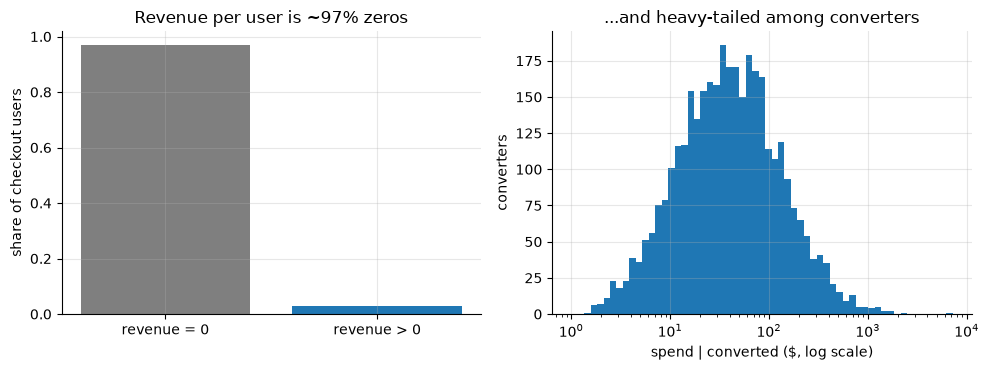

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].bar(["revenue = 0", "revenue > 0"],
            [np.mean(rev_hist == 0), np.mean(rev_hist > 0)], color=["tab:gray", "tab:blue"])
axes[0].set_ylabel("share of checkout users")
axes[0].set_title("Revenue per user is ~97% zeros")
axes[1].hist(aov_hist, bins=np.geomspace(1, aov_hist.max(), 60), color="tab:blue")
axes[1].set_xscale("log")
axes[1].set_xlabel("spend | converted ($, log scale)")
axes[1].set_ylabel("converters")
axes[1].set_title("...and heavy-tailed among converters")
plt.show()

### Choosing the primary metric: a variance argument, not a taste argument

Revenue per user is what the business ultimately cares about, so why not make it primary?
Because sample size scales with the **squared coefficient of variation** of the metric. For
a relative MDE $\delta$ at significance $\alpha$ and power $1-\beta$,

$$ n_\text{per arm} \;\approx\; 2\,(z_{1-\alpha/2} + z_{1-\beta})^2 \,\frac{\mathrm{CV}^2}{\delta^2}. $$

A binary metric with $p=0.03$ has $\mathrm{CV}=\sqrt{p(1-p)}/p \approx 5.7$. Revenue per
user — 97% zeros times a heavy-tailed lognormal — is far noisier per dollar of mean. Same
relative effect, dramatically different bill:

In [4]:
mde_rel = TRUE_EFFECT_PP / 0.030      # +0.2pp on 3.0% ~ +6.7% relative (design assumption)
z2 = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) ** 2   # (1.96 + 0.84)^2 ~ 7.85

candidates = pd.DataFrame({
    "metric": ["conversion (binary)", "revenue / user", "spend | converted (AOV)"],
    "mean": [p_hist, rev_hist.mean(), aov_hist.mean()],
    "CV": [np.sqrt(p_hist * (1 - p_hist)) / p_hist,
           rev_hist.std() / rev_hist.mean(),
           aov_hist.std() / aov_hist.mean()],
})
candidates["n_per_arm_for_+6.7%_rel"] = (2 * z2 * candidates["CV"] ** 2 / mde_rel ** 2).round(-2)
candidates["vs_conversion"] = (candidates["n_per_arm_for_+6.7%_rel"]
                               / candidates.loc[0, "n_per_arm_for_+6.7%_rel"]).round(2)
print(candidates.to_string(index=False))
print(f"\nrevenue/user needs ~{candidates.loc[1, 'vs_conversion']:.1f}x the sample of "
      "conversion for the same relative MDE")

                 metric    mean      CV  n_per_arm_for_+6.7%_rel  vs_conversion
    conversion (binary)  0.0297  5.7143                 115300.0           1.00
         revenue / user  2.4302 14.0058                 692800.0           6.01
spend | converted (AOV) 81.7857  2.2045                  17200.0           0.15

revenue/user needs ~6.0x the sample of conversion for the same relative MDE


Revenue per user needs roughly **6x** the sample of conversion for the same relative
effect on this historical week. A subtle extra strike against revenue: with heavy tails,
the CV *estimate itself* is unstable (this sample's whales pushed it above the DGP's true
~12), so even your power calculation for revenue is shakier than for a bounded binary
metric. (AOV's CV looks tame, but it is only measured on ~3% of users *and* its
denominator is itself random — it is a ratio metric, see
[05_ratio_metrics_delta_method.ipynb](./05_ratio_metrics_delta_method.ipynb) — so it is not
a primary-metric candidate either.)

**Decision, written in the design doc:**

- **Primary:** checkout conversion (per user). One primary metric, one test, α = 0.05.
- **Secondary:** revenue per user. We state *up front* that at the sample sized for
  conversion, revenue will be underpowered — we compute exactly how underpowered below, so
  nobody is surprised at readout time. This sentence prevents the "revenue is flat!" panic
  later.
- **Guardrails (non-inferiority, one-sided):** latency (margin +25 ms), support-contact
  rate (+0.10pp), refund rate among purchasers (+2pp).

### Power → sample size → duration

MDE comes from the business, not from statistics: the smallest lift that justifies the
engineering and maintenance cost of the new flow — here **+0.2pp absolute** (~6.7%
relative). With $p_1 q_1 + p_2 q_2$ in place of $2\bar p \bar q$ (the unpooled version):

$$ n_\text{per arm} = \frac{(z_{1-\alpha/2}+z_{1-\beta})^2\,(p_1 q_1 + p_2 q_2)}{\Delta^2} $$

The simulation-based view of power (and why analytic formulas can mislead for non-normal
metrics) is [02_power_mde_sample_size.ipynb](./02_power_mde_sample_size.ipynb)'s topic.

In [5]:
p1, mde_abs = 0.030, TRUE_EFFECT_PP
p2 = p1 + mde_abs
alpha, power = 0.05, 0.80

n_arm = int(np.ceil(z2 * (p1 * (1 - p1) + p2 * (1 - p2)) / mde_abs**2))
n_sm = NormalIndPower().solve_power(effect_size=proportion_effectsize(p2, p1),
                                    alpha=alpha, power=power, ratio=1.0)
daily_eligible = DAILY_LAMBDA.mean()
days_needed = 2 * n_arm / daily_eligible

print(f"required n per arm (exact unpooled formula): {n_arm:,}")
print(f"statsmodels cross-check (arcsine approx):    {n_sm:,.0f}")
print(f"eligible checkout traffic: ~{daily_eligible:,.0f} users/day "
      f"-> {days_needed:.1f} days -> run 14 days (two full weeks)")

# analytic power for the SECONDARY metric at that n (variance from historical logs)
rev_var = rev_hist.var()
delta_rev = mde_rel * rev_hist.mean()          # revenue moves with conversion if AOV is flat
se_rev = np.sqrt(2 * rev_var / n_arm)
power_rev = stats.norm.cdf(delta_rev / se_rev - Z975)
print(f"\nimplied revenue/user effect if AOV unchanged: +${delta_rev:.3f} per user")
print(f"power for revenue/user at n={n_arm:,}/arm: {power_rev:.0%}  <- state this in the design doc")

required n per arm (exact unpooled formula): 117,883
statsmodels cross-check (arcsine approx):    117,856
eligible checkout traffic: ~17,000 users/day -> 13.9 days -> run 14 days (two full weeks)

implied revenue/user effect if AOV unchanged: +$0.162 per user
power for revenue/user at n=117,883/arm: 21%  <- state this in the design doc


~118k users per arm, ~236k total. At ~17k eligible users/day that is ~14 days — and we run
**two full weeks** regardless of the arithmetic: traffic mix and conversion vary by day of
week (our DGP has both), and partial weeks over- or under-weight weekends. Note the last
line: at this sample size the revenue readout has **well under half** the power of the
conversion readout. Writing that down *before launch* is what makes the eventual "revenue
is not significant" a non-event instead of a crisis.

## 2. Run: the experiment data

We simulate 14 days of the experiment. Ground truth: treatment adds **+0.2pp** to every
user's conversion probability and changes nothing else (spend among converters, latency,
support contacts, refunds all untouched).

In [6]:
N_DAYS = 14
EXP_SALT = "checkout_v2"      # experiment-specific salt


def assign_bucket(uids, salt, n_buckets=100):
    """Deterministic hash-based bucketing: md5(salt:uid) -> bucket 0..n_buckets-1."""
    return np.array([int(hashlib.md5(f"{salt}:{u}".encode()).hexdigest()[:8], 16) % n_buckets
                     for u in uids])


pop = simulate_population(N_DAYS, rng, uid_prefix="u")
bucket = assign_bucket(pop["uid"], EXP_SALT)
treated = bucket >= 50                      # 50/50 split
exp = realize_outcomes(pop, treated, TRUE_EFFECT_PP, rng)

n_c, n_t = (~exp["treated"]).sum(), exp["treated"].sum()
print(f"{len(exp):,} users over {N_DAYS} days  |  control {n_c:,}  treatment {n_t:,}")
print(exp[["uid", "day", "device", "user_type", "browser", "app_build",
           "treated", "converted", "spend"]].head(5).to_string(index=False))
print(f"\nrealized conversion: control {exp.loc[~exp['treated'], 'converted'].mean():.4%}, "
      f"treatment {exp.loc[exp['treated'], 'converted'].mean():.4%}  (true effect +0.20pp)")

238,472 users over 14 days  |  control 118,991  treatment 119,481
     uid  day  device user_type browser app_build  treated  converted  spend
u0000000    0 desktop returning  safari   current     True      False    0.0
u0000001    0  mobile returning  safari   current    False      False    0.0
u0000002    0 desktop returning firefox   current    False      False    0.0
u0000003    0  mobile       new  safari   current     True      False    0.0
u0000004    0  mobile returning    edge   current    False      False    0.0

realized conversion: control 2.9809%, treatment 3.1838%  (true effect +0.20pp)


### Why hash-based assignment (and not `random()`)

Production experimentation platforms assign with a **deterministic hash** of
`salt:unit_id`, not with a random draw at request time, because:

- **Stateless and consistent.** Any service, on any machine, at any time computes the same
  assignment for a user — no shared assignment database, no race conditions, and the user
  sees a consistent experience across sessions and devices.
- **Auditable.** The analyst can recompute assignment offline from IDs alone and check the
  logs against it — which is exactly how you debug SRM.
- **Orthogonal experiments.** A different salt per experiment gives an independent split,
  so concurrent experiments don't confound each other (mutually exclusive experiments get
  a shared "layer" salt instead).

Two implementation traps worth naming in interviews: Python's built-in `hash()` is
randomized per process (`PYTHONHASHSEED`), so it silently breaks reproducibility — use a
cryptographic hash; and hashing raw sequential IDs *without a salt* recycles the same split
across every experiment, so "orthogonal" tests all share one confounded partition.

In [7]:
# determinism: same uid -> same bucket, every time, anywhere
u = exp["uid"].iloc[0]
print(f"uid {u}: bucket {assign_bucket([u], EXP_SALT)[0]} == "
      f"{assign_bucket([u], EXP_SALT)[0]} (recomputed)")

# independence across experiments: this experiment's split vs a hypothetical concurrent one
idx = rng.choice(len(exp), size=30_000, replace=False)
other = assign_bucket(exp["uid"].iloc[idx], "search_ranking_v7") >= 50
ours = treated[idx]
ct = pd.crosstab(ours, other, normalize="all")
chi2_ind = stats.chi2_contingency(pd.crosstab(ours, other))
print("\njoint split across two experiment salts (should be ~25% per cell):")
print(ct.round(4).to_string())
print(f"chi-square independence p = {chi2_ind.pvalue:.3f} -> splits are independent")

uid u0000000: bucket 83 == 83 (recomputed)

joint split across two experiment salts (should be ~25% per cell):
col_0   False   True 
row_0                
False  0.2462  0.2531
True   0.2497  0.2510
chi-square independence p = 0.331 -> splits are independent


## 3. Sanity checks before you read a single metric

### Sample-ratio mismatch (SRM)

We configured 50/50. SRM asks: **are the realized counts consistent with 50/50?** A
chi-square goodness-of-fit test on the two counts answers it. This is the cheapest, highest
-value check in experimentation: a failed SRM means the *composition* of the arms differs —
some process added or removed users asymmetrically — and every downstream comparison is
biased in an unknown direction. Industry convention alarms at **p < 0.001** (not 0.05: with
thousands of experiments checked daily, α = 0.05 would drown platforms in false alarms;
p < 0.001 fires ~once per 1,000 healthy experiments while real SRM p-values are typically
astronomically small).

In [8]:
def srm_test(n_control, n_treatment, expected=(0.5, 0.5)):
    total = n_control + n_treatment
    chi2, p = stats.chisquare([n_control, n_treatment],
                              [expected[0] * total, expected[1] * total])
    return chi2, p


chi2, p_srm = srm_test(n_c, n_t)
print(f"clean experiment: control {n_c:,} vs treatment {n_t:,} "
      f"({n_t / len(exp):.3%} treated)")
print(f"SRM chi-square = {chi2:.2f}, p = {p_srm:.3f} -> "
      f"{'PASS (no evidence of mismatch)' if p_srm > 0.001 else 'FAIL'}")

clean experiment: control 118,991 vs treatment 119,481 (50.103% treated)
SRM chi-square = 1.01, p = 0.316 -> PASS (no evidence of mismatch)


### Breaking the pipeline on purpose

Now the cautionary tale. Suppose that on **day 8** the mobile team ships a build that
crashes the *new* checkout for users on the legacy app version — their sessions die before
the exposure event is logged, so they silently vanish **from the treatment arm only**.
Legacy-build users are ~10% of traffic and convert worse than average, so this both
unbalances the arms *and* selectively removes low-converters from treatment.

In [9]:
broken_bug = exp["treated"] & (exp["app_build"] == "legacy") & (exp["day"] >= 8)
exp_broken = exp.loc[~broken_bug]

nb_c = (~exp_broken["treated"]).sum()
nb_t = exp_broken["treated"].sum()
chi2_b, p_b = srm_test(nb_c, nb_t)
print(f"broken pipeline: control {nb_c:,} vs treatment {nb_t:,} "
      f"({nb_t / len(exp_broken):.3%} treated)")
print(f"SRM chi-square = {chi2_b:.1f}, p = {p_b:.2e} -> glaring FAIL")

# what analyzing anyway would have cost us
d_clean = (exp.loc[exp["treated"], "converted"].mean()
           - exp.loc[~exp["treated"], "converted"].mean())
d_broken = (exp_broken.loc[exp_broken["treated"], "converted"].mean()
            - exp_broken.loc[~exp_broken["treated"], "converted"].mean())
print(f"\ntrue effect:                +{TRUE_EFFECT_PP * 100:.2f}pp")
print(f"clean-data estimate:        +{d_clean * 100:.2f}pp")
print(f"broken-data naive estimate: +{d_broken * 100:.2f}pp  "
      f"(overstated by {(d_broken - d_clean) / d_clean:+.0%} vs clean)")

broken pipeline: control 118,991 vs treatment 114,415 (49.020% treated)
SRM chi-square = 89.7, p = 2.75e-21 -> glaring FAIL

true effect:                +0.20pp
clean-data estimate:        +0.20pp
broken-data naive estimate: +0.26pp  (overstated by +29% vs clean)


The broken pipeline fails SRM at an astronomical significance level — SRM p-values from
real bugs are rarely subtle — and the naive estimate is inflated by nearly 30%,
because the users the bug deleted from treatment were below-average converters. **The bias
direction was not knowable in advance**; a bug that dropped high-intent users would have
masked a real win instead. That is why the response to SRM is *never* "the imbalance is
only 3%, the sample is huge, let's analyze anyway."

**Why SRM happens** (roughly in order of frequency): asymmetric logging/crash loss like our
bug; bot filtering that interacts with the treatment; redirects that drop query params or
add latency on one arm; triggering conditions evaluated *after* treatment diverges;
assignment changes mid-experiment (ramping re-bucketing); and data-pipeline joins/dedup
rules that treat arms differently.

**The response playbook:** (1) auto-block the readout — numbers from an SRM'd experiment
do not circulate; (2) localize the mismatch by segment and by time to find the mechanism;
(3) fix the root cause and **rerun**. Post-hoc patching (e.g., dropping the affected
segment from *both* arms) is a last resort that needs the mechanism to be fully understood
— and it changes the population your estimate applies to.

SRM localized by app build (broken data):
                n  treated_share   srm_p
app_build                               
current    214645         0.5015  0.1613
legacy      18761         0.3607  0.0000


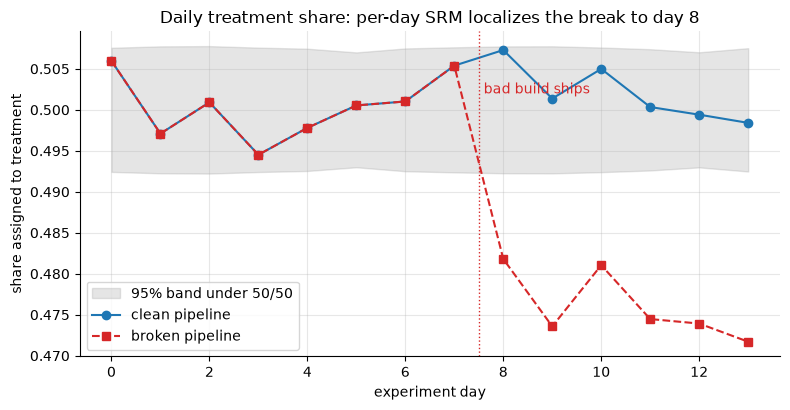

In [10]:
# Localize: SRM by segment finds WHO is missing; by day finds WHEN it started.
seg = (exp_broken.groupby("app_build")["treated"]
       .agg(n="size", treated_share="mean"))
seg["srm_p"] = [srm_test((g["treated"] == 0).sum(), g["treated"].sum())[1]
                for _, g in exp_broken.groupby("app_build")]
print("SRM localized by app build (broken data):")
print(seg.to_string())

daily = exp_broken.groupby("day")["treated"].agg(["size", "mean"])
daily_clean = exp.groupby("day")["treated"].agg(["size", "mean"])
band = Z975 * np.sqrt(0.25 / daily_clean["size"])

fig, ax = plt.subplots()
ax.fill_between(daily_clean.index, 0.5 - band, 0.5 + band, alpha=0.2, color="tab:gray",
                label="95% band under 50/50")
ax.plot(daily_clean.index, daily_clean["mean"], "o-", label="clean pipeline")
ax.plot(daily.index, daily["mean"], "s--", color="tab:red", label="broken pipeline")
ax.axvline(7.5, color="tab:red", lw=1, ls=":")
ax.annotate("bad build ships", xy=(7.6, 0.502), color="tab:red")
ax.set_xlabel("experiment day")
ax.set_ylabel("share assigned to treatment")
ax.set_title("Daily treatment share: per-day SRM localizes the break to day 8")
ax.legend()
plt.show()

The segment view says *legacy builds* are missing from treatment; the daily view says it
started on *day 8*. Cross-referencing deploys from day 8 finds the bug in minutes. Note
that segment-level SRM can fail even when the overall split passes (two bugs can cancel in
aggregate), so platforms run SRM per segment and per day routinely.

### A/A tests

An A/A test runs the full machinery — assignment, logging, metric pipeline, stats engine —
with **no treatment difference**. It validates the plumbing end-to-end: p-values should be
uniform, ~5% of A/A comparisons significant at α = 0.05, SRM passing. Platforms run A/A
continuously as regression tests, and A/A data doubles as the variance source for power
calculations. Here: one A/A split on the historical week (different salt, so it's an
independent partition), then 400 replicated A/A splits to check the p-value distribution.

A/A on historical week (n=118,998): SRM p = 0.698, conversion p = 0.246, revenue/user p = 0.169


400 A/A replications: 6.2% significant at 5% (expect ~5%), KS-vs-uniform p = 0.57


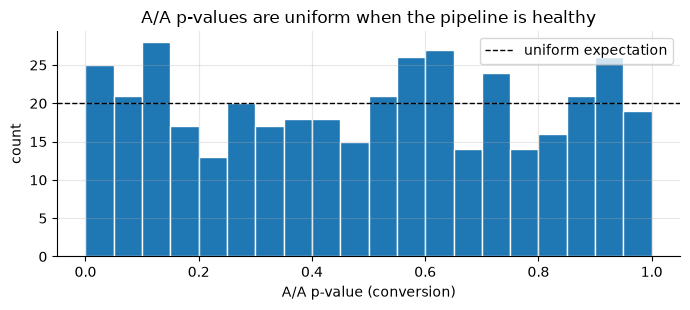

In [11]:
aa_treat = assign_bucket(hist["uid"], "checkout_v2_preflight_aa") >= 50
aa_c, aa_t = hist.loc[~aa_treat], hist.loc[aa_treat]
chi2_aa, p_aa = srm_test(len(aa_c), len(aa_t))
z_conv = stats.norm.sf(abs((aa_t["converted"].mean() - aa_c["converted"].mean())
                           / np.sqrt(hist["converted"].mean() * (1 - hist["converted"].mean())
                                     * (1 / len(aa_c) + 1 / len(aa_t))))) * 2
t_rev = stats.ttest_ind(aa_t["spend"], aa_c["spend"], equal_var=False)
print(f"A/A on historical week (n={len(hist):,}): SRM p = {p_aa:.3f}, "
      f"conversion p = {z_conv:.3f}, revenue/user p = {t_rev.pvalue:.3f}")

# 400 replicated A/A splits -> conversion p-values should be ~Uniform(0,1)
conv = hist["converted"].to_numpy()
pvals = np.empty(400)
for i in range(400):
    m = rng.random(conv.size) < 0.5
    pa, pb = conv[m].mean(), conv[~m].mean()
    pp_ = conv.mean()
    se0 = np.sqrt(pp_ * (1 - pp_) * (1 / m.sum() + 1 / (~m).sum()))
    pvals[i] = 2 * stats.norm.sf(abs((pa - pb) / se0))
ks = stats.kstest(pvals, "uniform")
print(f"400 A/A replications: {np.mean(pvals < 0.05):.1%} significant at 5% "
      f"(expect ~5%), KS-vs-uniform p = {ks.pvalue:.2f}")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(pvals, bins=20, range=(0, 1), color="tab:blue", edgecolor="white")
ax.axhline(400 / 20, color="black", ls="--", lw=1, label="uniform expectation")
ax.set_xlabel("A/A p-value (conversion)")
ax.set_ylabel("count")
ax.set_title("A/A p-values are uniform when the pipeline is healthy")
ax.legend()
plt.show()

## 4. Analyze: the experiment readout

SRM passed on the real experiment, so we may look at metrics. Method choices:

- **Conversion (and other binary metrics):** two-proportion z-test (pooled SE for the
  test), Wald CI (unpooled SE) for the absolute lift, and a **log-delta-method CI for the
  relative lift** — the naive `d/p_c` interval ignores the noise in the denominator and is
  asymmetric in the wrong way (details in
  [../01_statistical_foundations/02_hypothesis_testing_beyond_basics.ipynb](../01_statistical_foundations/02_hypothesis_testing_beyond_basics.ipynb)).
- **Revenue per user (heavy-tailed, 97% zeros):** Welch t-test — at ~119k per arm the CLT
  has done its work even for this distribution
  ([../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb](../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb))
  — cross-checked with a **bootstrap CI**, which is the honest default at smaller n or for
  statistics other than the mean. Never t-test the *median* or trim "outliers" that are
  real whales: you change the estimand.
- **Guardrails:** evaluated against their pre-registered non-inferiority margins (does the
  95% CI exclude a degradation larger than the margin?), not against p < 0.05.

In [12]:
def prop_metric(x_c, x_t):
    """Binary metric readout: absolute + relative lift with CIs, pooled-z p-value."""
    s_c, m_c, s_t, m_t = x_c.sum(), len(x_c), x_t.sum(), len(x_t)
    p_c, p_t = s_c / m_c, s_t / m_t
    d = p_t - p_c
    se = np.sqrt(p_c * (1 - p_c) / m_c + p_t * (1 - p_t) / m_t)      # unpooled, for the CI
    pool = (s_c + s_t) / (m_c + m_t)
    se0 = np.sqrt(pool * (1 - pool) * (1 / m_c + 1 / m_t))           # pooled, for the test
    pval = 2 * stats.norm.sf(abs(d / se0))
    se_log = np.sqrt((1 - p_c) / s_c + (1 - p_t) / s_t)              # delta method on log ratio
    rel_ci = np.exp(np.log(p_t / p_c) + np.array([-1, 1]) * Z975 * se_log) - 1
    return dict(c=p_c, t=p_t, d=d, lo=d - Z975 * se, hi=d + Z975 * se,
                rel=p_t / p_c - 1, rel_lo=rel_ci[0], rel_hi=rel_ci[1], p=pval)


def mean_metric(y_c, y_t):
    """Continuous metric readout: Welch t with Satterthwaite df, log-delta relative CI."""
    m_c, m_t = y_c.mean(), y_t.mean()
    v_c, v_t, k_c, k_t = y_c.var(ddof=1), y_t.var(ddof=1), len(y_c), len(y_t)
    d = m_t - m_c
    se = np.sqrt(v_c / k_c + v_t / k_t)
    df_w = se**4 / ((v_c / k_c) ** 2 / (k_c - 1) + (v_t / k_t) ** 2 / (k_t - 1))
    pval = 2 * stats.t.sf(abs(d / se), df_w)
    tcrit = stats.t.ppf(0.975, df_w)
    se_log = np.sqrt(v_c / (k_c * m_c**2) + v_t / (k_t * m_t**2))
    rel_ci = np.exp(np.log(m_t / m_c) + np.array([-1, 1]) * Z975 * se_log) - 1
    return dict(c=m_c, t=m_t, d=d, lo=d - tcrit * se, hi=d + tcrit * se,
                rel=m_t / m_c - 1, rel_lo=rel_ci[0], rel_hi=rel_ci[1], p=pval)


FMT = {
    "pct": (lambda v: f"{v:.3%}", lambda d: f"{d * 100:+.3f}pp"),
    "usd": (lambda v: f"${v:,.2f}", lambda d: f"${d:+,.3f}"),
    "ms": (lambda v: f"{v:,.0f}ms", lambda d: f"{d:+,.1f}ms"),
}


def readout_row(name, role, kind, res, margin=None):
    fv, fd = FMT[kind]
    if role.startswith("guardrail"):
        verdict = "PASS" if res["hi"] < margin else "FAIL"
        verdict += f" (worst case {fd(res['hi'])} vs margin {fd(margin)})"
    else:
        verdict = "significant" if res["p"] < 0.05 else "not significant"
    return {"metric": name, "role": role, "control": fv(res["c"]), "treatment": fv(res["t"]),
            "abs lift": fd(res["d"]), "95% CI (abs)": f"[{fd(res['lo'])}, {fd(res['hi'])}]",
            "rel lift": f"{res['rel']:+.2%}",
            "95% CI (rel)": f"[{res['rel_lo']:+.2%}, {res['rel_hi']:+.2%}]",
            "p": f"{res['p']:.2g}", "verdict": verdict}


C, T = exp.loc[~exp["treated"]], exp.loc[exp["treated"]]
raw = {
    "conversion": prop_metric(C["converted"], T["converted"]),
    "revenue_per_user": mean_metric(C["spend"], T["spend"]),
    "aov": mean_metric(C.loc[C["converted"], "spend"], T.loc[T["converted"], "spend"]),
    "latency": mean_metric(C["latency_ms"], T["latency_ms"]),
    "support": prop_metric(C["support_contact"], T["support_contact"]),
    "refund": prop_metric(C.loc[C["converted"], "refund"], T.loc[T["converted"], "refund"]),
}
scorecard = pd.DataFrame([
    readout_row("checkout conversion", "PRIMARY", "pct", raw["conversion"]),
    readout_row("revenue / user", "secondary", "usd", raw["revenue_per_user"]),
    readout_row("AOV (spend | converted)", "secondary, ratio", "usd", raw["aov"]),
    readout_row("checkout latency", "guardrail", "ms", raw["latency"], margin=25.0),
    readout_row("support contacts / user", "guardrail", "pct", raw["support"], margin=0.0010),
    readout_row("refund rate | converted", "guardrail, ratio", "pct", raw["refund"], margin=0.020),
]).set_index("metric")
print(f"=== Experiment scorecard: {EXP_SALT}, {N_DAYS} days, n = {len(exp):,} "
      f"(SRM p = {p_srm:.2f}) ===")
display(scorecard)

=== Experiment scorecard: checkout_v2, 14 days, n = 238,472 (SRM p = 0.32) ===


,role,control,treatment,abs lift,95% CI (abs),rel lift,95% CI (rel),p,verdict
metric,,,,,,,,,
checkout conversion,PRIMARY,2.981%,3.184%,+0.203pp,"[+0.064pp, +0.342pp]",+6.81%,"[+2.10%, +11.73%]",0.0042,significant
revenue / user,secondary,$2.40,$2.51,$+0.116,"[$-0.103, $+0.334]",+4.82%,"[-4.10%, +14.56%]",0.3,not significant
AOV (spend | converted),"secondary, ratio",$80.47,$78.97,$-1.499,"[$-7.613, $+4.614]",-1.86%,"[-9.10%, +5.95%]",0.63,not significant
checkout latency,guardrail,"1,202ms","1,200ms",-1.8ms,"[-5.7ms, +2.1ms]",-0.15%,"[-0.48%, +0.18%]",0.37,PASS (worst case +2.1ms vs margin +25.0ms)
support contacts / user,guardrail,0.838%,0.811%,-0.027pp,"[-0.099pp, +0.046pp]",-3.21%,"[-11.37%, +5.70%]",0.47,PASS (worst case +0.046pp vs margin +0.100pp)
refund rate | converted,"guardrail, ratio",5.949%,5.678%,-0.270pp,"[-1.341pp, +0.800pp]",-4.55%,"[-20.60%, +14.75%]",0.62,PASS (worst case +0.800pp vs margin +2.000pp)


Reading the scorecard like an experiment platform would:

- **Primary (conversion): significant.** The absolute lift's CI comfortably contains the
  true +0.20pp — as it should, we sized the test for exactly this effect. Always report
  both scales: engineers think in relative lift, finance models in absolute points.
- **Revenue per user: positive point estimate, CI includes zero.** This is *exactly* the
  ~20%-power outcome we predicted in the design doc, and the CI also includes the value
  implied by the conversion lift (checked below) — the data are fully consistent with a
  conversion-driven revenue gain. "Not significant" here is **absence of evidence**, not
  evidence of a flat revenue effect.
- **AOV: noisy and only a diagnostic.** It conditions on post-treatment conversion (both
  numerator population and denominator are affected by treatment), so it has no causal
  reading — Pitfall 1 shows how badly this can mislead.
- **Guardrails: all PASS** their non-inferiority margins. Note the refund guardrail's much
  wider CI — it lives on ~3% of users, which is why its margin had to be generous. A
  guardrail whose margin you could never realistically clear is theater, not protection.

revenue/user diff: +$0.116
  Welch 95% CI:     [$-0.103, $+0.334]
  bootstrap 95% CI: [$-0.098, $+0.330]   (2,000 resamples)
  effect implied by conversion lift x AOV: +$0.163 -> inside both CIs


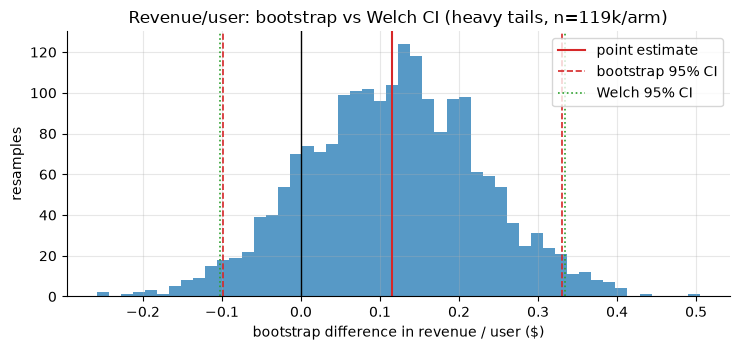

In [13]:
def bootstrap_mean_diff(x_c, x_t, n_boot=2000, chunk=100, rng=rng):
    """Percentile bootstrap for a difference in means, chunked to bound memory."""
    means = []
    for arr in (x_c, x_t):
        out = np.empty(n_boot)
        n = arr.size
        done = 0
        while done < n_boot:
            b = min(chunk, n_boot - done)
            idx = rng.integers(0, n, size=(b, n))
            out[done:done + b] = arr[idx].mean(axis=1)
            done += b
        means.append(out)
    return means[1] - means[0]


boot = bootstrap_mean_diff(C["spend"].to_numpy(), T["spend"].to_numpy())
b_lo, b_hi = np.percentile(boot, [2.5, 97.5])
r = raw["revenue_per_user"]
implied = raw["conversion"]["d"] * raw["aov"]["c"]  # conversion lift x control AOV

print(f"revenue/user diff: +${r['d']:.3f}")
print(f"  Welch 95% CI:     [${r['lo']:+.3f}, ${r['hi']:+.3f}]")
print(f"  bootstrap 95% CI: [${b_lo:+.3f}, ${b_hi:+.3f}]   (2,000 resamples)")
print(f"  effect implied by conversion lift x AOV: +${implied:.3f} -> inside both CIs")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.hist(boot, bins=50, color="tab:blue", alpha=0.75)
ax.axvline(0, color="black", lw=1)
ax.axvline(r["d"], color="tab:red", lw=1.5, label="point estimate")
for v, ls, lab in [(b_lo, "--", "bootstrap 95% CI"), (b_hi, "--", None),
                   (r["lo"], ":", "Welch 95% CI"), (r["hi"], ":", None)]:
    ax.axvline(v, color="tab:red" if ls == "--" else "tab:green", ls=ls, lw=1.2, label=lab)
ax.set_xlabel("bootstrap difference in revenue / user ($)")
ax.set_ylabel("resamples")
ax.set_title("Revenue/user: bootstrap vs Welch CI (heavy tails, n=119k/arm)")
ax.legend()
plt.show()

Welch and bootstrap agree to the cent here — at 119k users per arm the CLT has tamed even
a 97%-zero lognormal. The bootstrap earns its keep when n is small, the statistic is not a
mean (quantiles, ratios), or you want to *check* rather than assume normality
([../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb](../01_statistical_foundations/01_sampling_clt_bootstrap.ipynb)).

One more standard readout plot: the cumulative lift by day. Reviewers use it to check the
estimate has stabilized and shows no novelty-style decay (Section 6) — **not** to decide
when to stop; that decision was made by the power calculation, and "stop when the daily
chart looks significant" is the peeking trap dissected in
[04_peeking_sequential.ipynb](./04_peeking_sequential.ipynb).

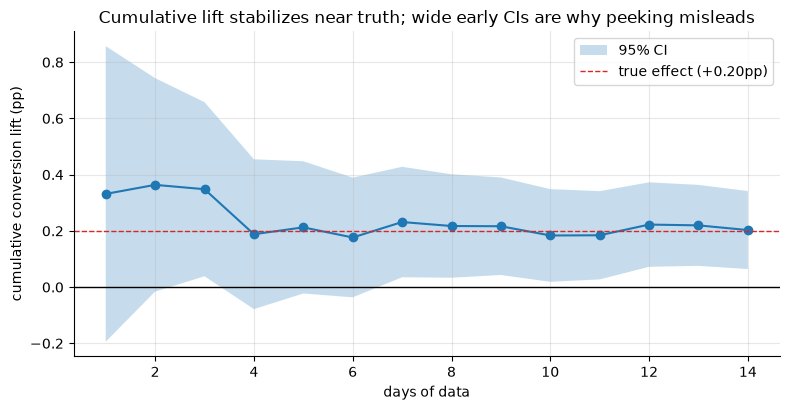

In [14]:
cum = []
for d_ in range(N_DAYS):
    sub = exp[exp["day"] <= d_]
    res = prop_metric(sub.loc[~sub["treated"], "converted"], sub.loc[sub["treated"], "converted"])
    cum.append({"day": d_ + 1, "lift": res["d"], "lo": res["lo"], "hi": res["hi"]})
cum = pd.DataFrame(cum)

fig, ax = plt.subplots()
ax.fill_between(cum["day"], cum["lo"] * 100, cum["hi"] * 100, alpha=0.25, label="95% CI")
ax.plot(cum["day"], cum["lift"] * 100, "o-")
ax.axhline(TRUE_EFFECT_PP * 100, color="tab:red", ls="--", lw=1, label="true effect (+0.20pp)")
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("days of data")
ax.set_ylabel("cumulative conversion lift (pp)")
ax.set_title("Cumulative lift stabilizes near truth; wide early CIs are why peeking misleads")
ax.legend()
plt.show()

## 5. Segments: pre-registered cuts vs post-hoc fishing

The design doc pre-registered exactly two segment dimensions with a mechanism story:
**device** (the redesign changed mobile layout most) and **user type** (new users lack
saved payment methods). For pre-registered cuts the right question is *"do the segment
effects differ?"* — an **interaction test** on the difference in lifts — not *"which
segments are individually significant?"*. With half the sample each, segments have far
less power, so "significant in A, not in B" is the expected outcome even under identical
effects — the classic *difference-in-significance* fallacy.

pre-registered segments (true effect is +0.20pp in every one):
           lift_pp              ci      p
segment                                  
mobile       0.154  [-0.01, +0.32]  0.065
desktop      0.281  [+0.03, +0.53]  0.028
new          0.161  [-0.03, +0.35]  0.094
returning    0.237  [+0.04, +0.44]  0.020
interaction mobile vs desktop: z = -0.84, p = 0.40 -> no evidence effects differ
interaction new vs returning: z = -0.54, p = 0.59 -> no evidence effects differ


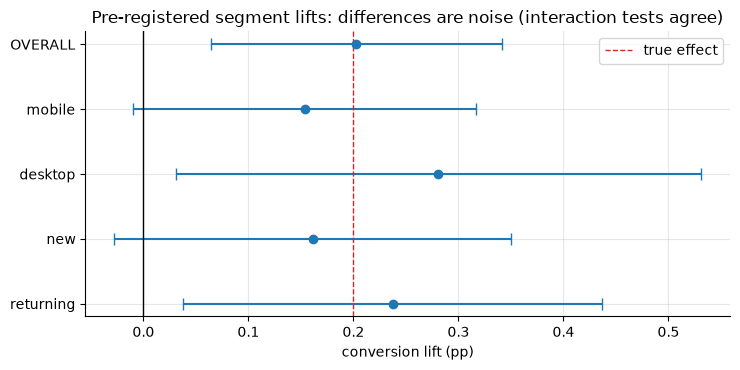

In [15]:
def segment_lift(df, col, level):
    s = df[df[col] == level]
    return prop_metric(s.loc[~s["treated"], "converted"], s.loc[s["treated"], "converted"])


def interaction_z(r1, r2):
    se1 = (r1["hi"] - r1["lo"]) / (2 * Z975)
    se2 = (r2["hi"] - r2["lo"]) / (2 * Z975)
    z = (r1["d"] - r2["d"]) / np.sqrt(se1**2 + se2**2)
    return z, 2 * stats.norm.sf(abs(z))


rows, results = [], {}
for col, levels in [("device", ["mobile", "desktop"]), ("user_type", ["new", "returning"])]:
    for lv in levels:
        res = segment_lift(exp, col, lv)
        results[lv] = res
        rows.append({"segment": lv, "lift_pp": res["d"] * 100,
                     "ci": f"[{res['lo'] * 100:+.2f}, {res['hi'] * 100:+.2f}]",
                     "p": res["p"]})
seg_df = pd.DataFrame(rows).set_index("segment")
print("pre-registered segments (true effect is +0.20pp in every one):")
print(seg_df.round(3).to_string())
for a, b in [("mobile", "desktop"), ("new", "returning")]:
    z, p_int = interaction_z(results[a], results[b])
    print(f"interaction {a} vs {b}: z = {z:+.2f}, p = {p_int:.2f} -> no evidence effects differ")

overall = raw["conversion"]
labels = ["OVERALL"] + list(seg_df.index)
lifts = [overall["d"] * 100] + list(seg_df["lift_pp"])
los = [overall["lo"] * 100] + [results[s]["lo"] * 100 for s in seg_df.index]
his = [overall["hi"] * 100] + [results[s]["hi"] * 100 for s in seg_df.index]

fig, ax = plt.subplots(figsize=(7.5, 3.8))
y = np.arange(len(labels))[::-1]
ax.errorbar(lifts, y, xerr=[np.array(lifts) - np.array(los), np.array(his) - np.array(lifts)],
            fmt="o", capsize=4, color="tab:blue")
ax.axvline(0, color="black", lw=1)
ax.axvline(TRUE_EFFECT_PP * 100, color="tab:red", ls="--", lw=1, label="true effect")
ax.set_yticks(y, labels)
ax.set_xlabel("conversion lift (pp)")
ax.set_title("Pre-registered segment lifts: differences are noise (interaction tests agree)")
ax.legend()
plt.show()

### Post-hoc scanning, and why it needs discipline

Now the thing that actually happens after every readout: someone opens the dashboard's
segment explorer and slices lift by browser, day of week, zodiac sign... Our ground truth
is a *constant* +0.2pp everywhere, so any "segment where it works 3x better" — or "where
it backfires" — is pure noise. (Our own pre-registered table above already demonstrated
the fallacy live: desktop crossed p < 0.05 and mobile did not, yet the interaction test
found nothing.) We scan browser x day-of-week (35 segments), testing each segment's lift against
the rest of the population (an interaction test — under constant effect, all 35 nulls are
true), then apply the multiple-testing machinery from
[../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb).

In [16]:
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
tot = exp.groupby("treated")["converted"].agg(["sum", "size"])


def _lift_se(s_c, m_c, s_t, m_t):
    """Absolute lift and its (unpooled) standard error from success/total counts."""
    p_c, p_t = s_c / m_c, s_t / m_t
    return p_t - p_c, np.sqrt(p_c * (1 - p_c) / m_c + p_t * (1 - p_t) / m_t)


scan = []
for (br, dw), g in exp.groupby(["browser", "dow"]):
    gs = g.groupby("treated")["converted"].agg(["sum", "size"])
    if (gs["size"] < 200).any():
        continue
    # segment vs rest interaction on the absolute lift
    d_s, se_s = _lift_se(gs.loc[False, "sum"], gs.loc[False, "size"],
                         gs.loc[True, "sum"], gs.loc[True, "size"])
    rest = tot - gs
    d_r, se_r = _lift_se(rest.loc[False, "sum"], rest.loc[False, "size"],
                         rest.loc[True, "sum"], rest.loc[True, "size"])
    z = (d_s - d_r) / np.sqrt(se_s**2 + se_r**2)
    scan.append({"segment": f"{br} x {dow_names[dw]}", "n": int(gs['size'].sum()),
                 "lift_pp": d_s * 100, "z_vs_rest": z, "p": 2 * stats.norm.sf(abs(z))})

scan = pd.DataFrame(scan).sort_values("p").reset_index(drop=True)
n_naive = (scan["p"] < 0.05).sum()
holm = multipletests(scan["p"], alpha=0.05, method="holm")[0]
bh = multipletests(scan["p"], alpha=0.05, method="fdr_bh")[0]
print(f"scanned {len(scan)} post-hoc segments (all nulls true by construction)")
print(f"'significant' interactions at raw p<0.05: {n_naive}  |  "
      f"after Holm: {holm.sum()}  |  after BH(FDR): {bh.sum()}")
print("\ntop 5 by p-value — the dashboard 'discoveries':")
print(scan.head(5).round(4).to_string(index=False))

top = scan.iloc[0]
print(f"\nthe pitch that writes itself: \"lift is {top['lift_pp']:+.2f}pp for {top['segment']} "
      f"users (vs +{overall['d'] * 100:.2f}pp overall, p={top['p']:.3f})\" — and it is pure noise.")

scanned 35 post-hoc segments (all nulls true by construction)
'significant' interactions at raw p<0.05: 2  |  after Holm: 0  |  after BH(FDR): 0

top 5 by p-value — the dashboard 'discoveries':
      segment     n  lift_pp  z_vs_rest      p
  other x Thu  1962  -1.4771    -2.1676 0.0302
   edge x Thu  2931  -1.1486    -2.1629 0.0306
firefox x Thu  3421  -0.8798    -1.8711 0.0613
 chrome x Fri 16621   0.6612     1.7789 0.0752
 chrome x Mon 16069   0.5988     1.5100 0.1311

the pitch that writes itself: "lift is -1.48pp for other x Thu users (vs +0.20pp overall, p=0.030)" — and it is pure noise.


The scan "finds" segments at raw p < 0.05 — as ~5% of 35 true nulls must — and the
corrections wipe them out. Note that with this seed the top "discovery" is a scary
*negative* segment, exactly the kind that triggers a ship-block demand in the review
meeting; it is as fake as the positive ones. The senior discipline:

- **Pre-registered segments**: few, mechanism-motivated, analyzed with interaction tests,
  reported with the primary result.
- **Post-hoc segments**: hypothesis *generation* only. Correct for multiplicity (Holm for
  a handful of decisions, BH when scanning hundreds), and even survivors get re-tested in
  a follow-up experiment before anyone changes a roadmap. Remember the **winner's curse**:
  the estimated lift in a segment *selected for significance* is biased upward
  ([../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb)
  quantifies the exaggeration).
- Genuine heterogeneous-effect estimation is a modeling problem, not a scanning problem —
  see [../03_causal_inference/05_uplift_cate.ipynb](../03_causal_inference/05_uplift_cate.ipynb).

## 6. Novelty and primacy effects

Our checkout test measures a *friction* mechanism, which is usually stable. But many UI
changes show **novelty** (users click the shiny new thing, effect decays) or **primacy**
(users need time to relearn, effect grows). The standard diagnostic: estimate the lift as
a function of **days since the user's first exposure** — not calendar time — because
calendar-day lift mixes new arrivals (exposure age 0) with veterans. We simulate a
recommendations-carousel experiment under both a constant effect and a decaying novelty
effect on daily purchase rate, with users returning across days.

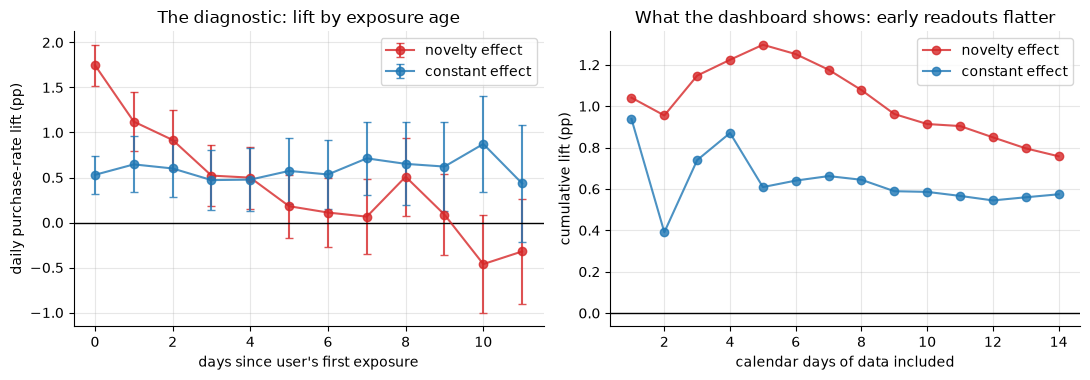

In [17]:
def simulate_engagement(effect, rng, n_users=80_000, n_days=14, p_daily=0.02):
    """Users arrive on a random day, revisit with prob 0.5/day; treatment scales p_daily."""
    arrival = rng.integers(0, n_days, n_users)
    treated_u = rng.random(n_users) < 0.5
    days = np.arange(n_days)
    revisit = rng.random((n_users, n_days)) < 0.5
    active = (days >= arrival[:, None]) & (revisit | (days == arrival[:, None]))
    dse = days - arrival[:, None]                      # days since first exposure
    if effect == "novelty":
        mult = 1 + 0.8 * np.exp(-np.maximum(dse, 0) / 3.0)   # +80% day 0, decaying
    else:
        mult = np.full_like(dse, 1.3, dtype=float)           # constant +30%
    p = p_daily * np.where(treated_u[:, None], mult, 1.0)
    buy = active & (rng.random((n_users, n_days)) < p)
    m = active
    return pd.DataFrame({"day": np.broadcast_to(days, active.shape)[m],
                         "dse": dse[m],
                         "treated": np.broadcast_to(treated_u[:, None], active.shape)[m],
                         "buy": buy[m]})


def lift_by(df, col, max_val):
    out = []
    for v in range(max_val + 1):
        s = df[df[col] == v] if col == "dse" else df[df["day"] <= v]
        g = s.groupby("treated")["buy"].agg(["mean", "size"])
        d = g.loc[True, "mean"] - g.loc[False, "mean"]
        se = np.sqrt(sum(g.loc[a, "mean"] * (1 - g.loc[a, "mean"]) / g.loc[a, "size"]
                         for a in (False, True)))
        out.append({col: v, "lift_pp": d * 100, "err": Z975 * se * 100})
    return pd.DataFrame(out)


nov = simulate_engagement("novelty", rng)
con = simulate_engagement("constant", rng)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for df_, lab, col in [(nov, "novelty effect", "tab:red"), (con, "constant effect", "tab:blue")]:
    by_dse = lift_by(df_, "dse", 11)
    axes[0].errorbar(by_dse["dse"], by_dse["lift_pp"], yerr=by_dse["err"],
                     fmt="o-", capsize=3, label=lab, color=col, alpha=0.8)
    by_day = lift_by(df_, "day", 13)
    axes[1].plot(by_day["day"] + 1, by_day["lift_pp"], "o-", label=lab, color=col, alpha=0.8)
axes[0].axhline(0, color="black", lw=1)
axes[0].set_xlabel("days since user's first exposure")
axes[0].set_ylabel("daily purchase-rate lift (pp)")
axes[0].set_title("The diagnostic: lift by exposure age")
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xlabel("calendar days of data included")
axes[1].set_ylabel("cumulative lift (pp)")
axes[1].set_title("What the dashboard shows: early readouts flatter")
for ax in axes:
    ax.legend()
plt.show()

Left: the exposure-age curve is flat for the constant effect and decays toward zero for
the novelty effect — that slope is the test. Right: the consequence for readouts — the
novelty experiment's cumulative lift at day 3 is roughly double its day-14 value, so an
impatient early ship decision would bake in a number the feature will never deliver in
steady state. Responses when the exposure-age curve decays: run longer and weight
later-exposure cohorts; estimate the *asymptote*, not the average; and validate with a
**long-term holdout** (keep a small percent on control after shipping). Primacy is the
mirror image — an early flat/negative readout can hide a real long-run win.

## 7. Decision: statistical significance is one input, not the answer

The ship decision weighs four separate things — conflating them is the most common
experiment-review failure:

1. **Statistical significance** of the *primary* metric (did we measure a real effect?).
2. **Practical significance**: is the effect, at the CI's *lower* bound too, worth the
   engineering, latency, and complexity cost? A significant +0.01pp is a no-ship; a
   non-significant CI of [-0.1pp, +2pp] on a cheap change is "extend or rerun", not "kill".
3. **Guardrails**: non-inferiority passed, including the wide-CI ones?
4. **Validity checks**: SRM, A/A history, stability over time, no unexplained
   heterogeneity, and **Twyman's law** — a result that looks too good is more likely a bug
   than a breakthrough; investigate before celebrating.

In [18]:
ANNUAL_CHECKOUT_USERS = int(DAILY_LAMBDA.mean() * 365)
aov_c = raw["aov"]["c"]
conv_res = raw["conversion"]

impact = {k: ANNUAL_CHECKOUT_USERS * conv_res[k] * aov_c for k in ("d", "lo", "hi")}
print("=== Decision summary: checkout_v2 ===")
print(f"primary   conversion: {conv_res['d'] * 100:+.2f}pp "
      f"[{conv_res['lo'] * 100:+.2f}, {conv_res['hi'] * 100:+.2f}] "
      f"(rel {conv_res['rel']:+.1%}), p = {conv_res['p']:.2g} -> significant, "
      f"and practically meaningful even at the CI lower bound (see impact below)")
print(f"secondary revenue/user: +${raw['revenue_per_user']['d']:.3f} "
      f"[{raw['revenue_per_user']['lo']:+.3f}, {raw['revenue_per_user']['hi']:+.3f}] "
      "-> underpowered as pre-declared; consistent with conversion-driven gain")
print("guardrails: latency, support contacts, refunds all within margins")
print(f"\nprojected annual gross impact (conversion lift x control AOV x "
      f"{ANNUAL_CHECKOUT_USERS / 1e6:.1f}M checkout users/yr):")
print(f"  ${impact['d'] / 1e6:.2f}M  [95% CI ${impact['lo'] / 1e6:.2f}M, "
      f"${impact['hi'] / 1e6:.2f}M]")
print("  (projection caveats: assumes AOV unchanged — supported, not proven, by this test —")
print("   and a single 2-week window generalizing across the year; both go in the report.)")
print("\nRECOMMENDATION: SHIP, with a 5% long-term holdout for 8 weeks to verify persistence.")

=== Decision summary: checkout_v2 ===
primary   conversion: +0.20pp [+0.06, +0.34] (rel +6.8%), p = 0.0042 -> significant, and practically meaningful even at the CI lower bound (see impact below)
secondary revenue/user: +$0.116 [-0.103, +0.334] -> underpowered as pre-declared; consistent with conversion-driven gain
guardrails: latency, support contacts, refunds all within margins

projected annual gross impact (conversion lift x control AOV x 6.2M checkout users/yr):
  $1.01M  [95% CI $0.32M, $1.71M]
  (projection caveats: assumes AOV unchanged — supported, not proven, by this test —
   and a single 2-week window generalizing across the year; both go in the report.)

RECOMMENDATION: SHIP, with a 5% long-term holdout for 8 weeks to verify persistence.


**What goes in the experiment report** (the artifact your VP forwards): TL;DR with the
recommendation and the projected impact *as an interval*; design summary (hypothesis, MDE,
power, dates, n); the scorecard with CIs on both scales; validity section (SRM, A/A,
stability plot); pre-registered segment readout with interaction tests; any post-hoc
observations clearly labeled "hypothesis-generating, multiplicity-corrected"; decision
rationale against the pre-registered bar; and follow-ups (holdout plan, iteration ideas).
Numbers that did not come with a CI do not go in the report.

For the Bayesian version of this readout — posterior on the lift, expected loss of
shipping, P(treatment better) for the PM who keeps asking — see
[../06_bayesian_methods/01_bayesian_ab_testing.ipynb](../06_bayesian_methods/01_bayesian_ab_testing.ipynb).
For marketplaces or social products where treating some users contaminates others
(interference breaking SUTVA), see
[06_advanced_designs_interference.ipynb](./06_advanced_designs_interference.ipynb).

## 8. Pitfalls

We already demonstrated two big ones: *analyzing through an SRM* (Section 3 — a ~30%
inflated estimate) and *fishing segments without correction* (Section 5). Three more that
routinely burn experiment reviews:

### Pitfall 1: treating converter-conditioned metrics (AOV) as causal

A treatment that converts *marginal* users — hesitant, lower-basket shoppers who would
have bounced — mechanically drags AOV down even though **no individual spends less**.
Conditioning on conversion (a post-treatment variable) compares different populations;
it is the selection/collider trap from
[../03_causal_inference/01_potential_outcomes_dags.ipynb](../03_causal_inference/01_potential_outcomes_dags.ipynb).
Watch a strictly-good treatment "significantly hurt" AOV:

In [19]:
n_pit = 200_000
u_c, u_t = rng.random(n_pit), rng.random(n_pit)
# control: 3.0% convert, spend ~ mean $80
conv_c = u_c < 0.030
spend_c = np.zeros(n_pit)
spend_c[conv_c] = rng.lognormal(SPEND_MU, SPEND_SIGMA, conv_c.sum())
# treatment: same 3.0% core converters (same spend dist) + 0.6pp NEW marginal converters
# who spend ~ mean $35. Nobody's spend decreases; revenue strictly increases.
conv_core = u_t < 0.030
conv_marg = (u_t >= 0.030) & (u_t < 0.036)
spend_t = np.zeros(n_pit)
spend_t[conv_core] = rng.lognormal(SPEND_MU, SPEND_SIGMA, conv_core.sum())
spend_t[conv_marg] = rng.lognormal(np.log(35) - SPEND_SIGMA**2 / 2, SPEND_SIGMA, conv_marg.sum())
conv_t = conv_core | conv_marg

pit = pd.DataFrame([
    readout_row("conversion", "primary", "pct", prop_metric(conv_c, conv_t)),
    readout_row("revenue / user", "secondary", "usd", mean_metric(spend_c, spend_t)),
    readout_row("AOV (spend | converted)", "diagnostic", "usd",
                mean_metric(spend_c[conv_c], spend_t[conv_t])),
]).set_index("metric")[["control", "treatment", "abs lift", "rel lift", "p", "verdict"]]
display(pit)
print("AOV is 'significantly' down while every user's spend is unchanged or higher.")
print("Decide on per-randomized-unit metrics; use AOV only to *explain* the revenue math.")

,control,treatment,abs lift,rel lift,p,verdict
metric,,,,,,
conversion,3.013%,3.620%,+0.607pp,+20.15%,8.2e-27,significant
revenue / user,$2.40,$2.51,$+0.111,+4.62%,0.21,not significant
AOV (spend | converted),$79.74,$69.43,$-10.306,-12.92%,2.6e-05,significant


AOV is 'significantly' down while every user's spend is unchanged or higher.
Decide on per-randomized-unit metrics; use AOV only to *explain* the revenue math.


### Pitfall 2: analyzing users who could never see the change (dilution)

Suppose the next iteration only triggers for carts over \$50 — about 30% of checkout
users. If you randomize and analyze **all** checkout users, the 70% who never trigger
contribute full variance (they convert through the normal flow!) and zero signal: the
+0.2pp effect among triggered users shrinks to +0.06pp in the analysis population, and
required sample explodes roughly as $1/r^2$ against variance shrinking only as ~$1/r$:

In [20]:
r_trig = 0.30
p_trig, d_trig = 0.030, 0.002                 # effect among triggered users
p_all, d_all = 0.030, d_trig * r_trig         # untriggered still convert at ~3% via old flow

def n_per_arm(p_base, d):
    pa, pb = p_base, p_base + d
    return z2 * (pa * (1 - pa) + pb * (1 - pb)) / d**2

n_trig_only = n_per_arm(p_trig, d_trig)
n_all_users = n_per_arm(p_all, d_all)
days_trig = 2 * n_trig_only / (daily_eligible * r_trig)   # only 30% of traffic counts
days_all = 2 * n_all_users / daily_eligible
print(f"analyze triggered only: n/arm = {n_trig_only:,.0f} -> {days_trig:.0f} days")
print(f"analyze all users:      n/arm = {n_all_users:,.0f} -> {days_all:.0f} days "
      f"({days_all / days_trig:.1f}x longer)")

analyze triggered only: n/arm = 117,882 -> 46 days
analyze all users:      n/arm = 1,281,191 -> 151 days (3.3x longer)


Triggered-only analysis is ~3x faster *in calendar time* — so instrument the trigger event
and randomize (or at least analyze) at the trigger. One senior nuance: this argument needs
the untriggered users to carry outcome variance. In the edge case where untriggered users
*cannot* convert at all (outcome identically zero), rare-event dilution costs sample size
but almost no power at fixed calendar time — the information lives in the conversions,
which are unchanged. Know which regime you are in before promising a faster test. Either
way, the trigger condition must be computable **identically in both arms** (a
treatment-only trigger event is an SRM machine).

### Pitfall 3: "revenue wasn't significant, so the feature doesn't make money"

Our own scorecard is the counterexample: revenue's CI spans zero *and* the +\$0.16-ish
value implied by the conversion lift — the design doc predicted ~20% power for revenue, so
a non-significant readout was the *expected outcome under a true effect*. The claim "no
revenue impact" requires an interval that **excludes** meaningful effects, not a failed
significance test. Report the CI, point at the pre-declared power, and if the revenue
question must be answered directly, that is a variance-reduction problem
([03_variance_reduction_cuped.ipynb](./03_variance_reduction_cuped.ipynb)) or a longer
test — not a shrug. The same logic read in the other direction: do not *extend* a running
test until significance appears; that is the peeking pathology of
[04_peeking_sequential.ipynb](./04_peeking_sequential.ipynb).

## 9. The senior experiment-review checklist

What a senior reviewer walks through, in order — most experiments die in the first block:

**Design (before launch)**
- Falsifiable hypothesis with a mechanism; one pre-registered primary metric.
- Unit of randomization matches the unit of analysis (else: clustered SEs / delta method,
  [05_ratio_metrics_delta_method.ipynb](./05_ratio_metrics_delta_method.ipynb)).
- MDE from business economics; power calc documented; duration = full weeks; trigger
  condition computable identically in both arms.
- Guardrails with explicit non-inferiority margins someone signed off on.

**Validity (before reading metrics)**
- SRM overall, by key segments, by day — at p < 0.001, with auto-block.
- A/A history healthy; assignment reproducible offline from IDs (hash + salt).
- Any mid-experiment config change, ramp, or deploy? If yes, treat the readout as suspect.

**Analysis**
- Pre-registered plan followed; CIs on absolute and relative scales; heavy-tailed metrics
  cross-checked with bootstrap; conditional/ratio metrics labeled as diagnostics.
- Segment claims backed by interaction tests and multiplicity correction.
- No peeking-based stopping ([04_peeking_sequential.ipynb](./04_peeking_sequential.ipynb));
  variance reduction applied where planned ([03_variance_reduction_cuped.ipynb](./03_variance_reduction_cuped.ipynb)).

**Decision**
- Practical significance argued at the CI lower bound, against cost.
- Guardrail pass/fail stated; exposure-age curve checked for novelty/primacy.
- Twyman's law applied to surprises; long-term holdout planned for big ships.
- The report states what would change the decision (new evidence, holdout results).

## Interview corner

**1. "Walk me through designing an experiment for feature X."**
Structure beats trivia: hypothesis + mechanism -> population and trigger -> unit of
randomization (user; note clustering if it isn't) -> primary metric (sensitive, proximate
to the mechanism, low variance — argue conversion vs revenue via CV²) -> guardrails with
margins -> MDE from business value -> power -> n -> duration in full weeks -> assignment
(hashed, salted) -> validity checks (SRM, A/A) -> pre-registered analysis plan -> decision
rule agreed before launch. Interviewers listen for the *order* (metric and MDE before
sample size) and for guardrails and SRM appearing unprompted.

**2. "What is SRM? Why does it happen, and what do you do?"**
Realized assignment counts inconsistent with the configured split (chi-square, alarm at
p < 0.001). Causes: asymmetric logging/crash loss, bot filters interacting with treatment,
redirects, post-treatment triggering, mid-test ramp changes, pipeline joins. Response:
block the readout — composition bias of unknown direction — localize by segment x time,
fix, rerun. Strong candidates volunteer a war story and the p < 0.001 convention; weak
ones say "rebalance the data".

**3. "Conversion is up and significant, revenue is flat. Ship?"**
First reframe "flat": non-significant ≠ zero. Check the design doc's power for revenue
(here ~20%); check the revenue CI contains the conversion-implied effect (it does — the
data are consistent, revenue is just noisy); check AOV *as a diagnostic* for a
marginal-buyer composition shift. If the primary was conversion and guardrails pass:
ship, and monitor revenue in a long-term holdout. If revenue genuinely is the decision
metric, the test was mis-designed — size for it or add CUPED next time.

**4. "Why hash-based assignment instead of calling random() at request time?"**
Deterministic, stateless, consistent across services/sessions/devices; auditable offline
(recompute from IDs — that's how you debug SRM); per-experiment salts give independent
splits for concurrent tests, layers give mutual exclusivity. Bonus points: Python `hash()`
is process-seeded (non-reproducible); unsalted hashing reuses one split across all
experiments.

**5. "The effect is significant on mobile but not on desktop. Do we report a
mobile-only effect?"**
No — that is a difference in significance, not a significant difference. Run the
interaction test on the lift difference; with half the sample per segment, power halves,
so this pattern arises constantly under identical effects. If the interaction *is* real
and pre-registered, report both with CIs; if it emerged from scanning, correct for
multiplicity and re-test before acting (winner's curse).

**6. "The test hit significance on day 4 of 14. Can we stop and ship?"**
No — the day-4 "significance" came from repeated looking, which inflates false positives
far above α, and early estimates are inflated conditional on crossing (winner's curse);
also day 4 has seen no full weekly cycle and over-weights heavy users and novelty. Either
run the fixed-horizon test to completion or use a *pre-registered* sequential design
(group-sequential/mSPRT — [04_peeking_sequential.ipynb](./04_peeking_sequential.ipynb)).

**7. "The PM asks: what's the probability the treatment is actually better?"**
A p-value doesn't answer that — it's P(data at least this extreme | H0), not P(H1 | data).
Answer it properly with a posterior: P(lift > 0 | data) and expected loss of shipping,
from [../06_bayesian_methods/01_bayesian_ab_testing.ipynb](../06_bayesian_methods/01_bayesian_ab_testing.ipynb).
The frequentist near-equivalent statement is the CI plus the pre-registered decision rule.

## Key takeaways

- Write the design doc first: hypothesis, one primary metric, MDE from economics, power,
  duration in full weeks, guardrails with margins, decision rule. Pre-declare the power of
  secondary metrics so "revenue is flat" is a non-event.
- Primary-metric choice is a variance argument: required n scales with CV²/δ²; per-user
  conversion (~CV 5.7 here) beats zero-inflated heavy-tailed revenue (~CV 14, ~6x the n).
- Randomize users with a salted cryptographic hash: deterministic, auditable, orthogonal
  across experiments.
- SRM is the first thing you check and an absolute readout-blocker at p < 0.001. Localize
  by segment and day; fix and rerun — our simulated crash bug inflated the lift ~30%.
- A/A tests validate the whole pipeline: uniform p-values, ~5% false positives, and free
  variance estimates for power calcs.
- Report absolute *and* relative lift with CIs; use delta-method intervals for ratios and
  bootstrap cross-checks for heavy tails.
- Converter-conditioned metrics (AOV, refund rate among buyers) are diagnostics, not
  causal readouts — composition shifts masquerade as effects.
- Segments: pre-registered + interaction tests, or corrected + re-tested. Difference in
  significance is not significance of difference.
- Check the exposure-age curve for novelty/primacy before extrapolating a 2-week number to
  a year; validate big ships with long-term holdouts.
- Ship decisions weigh statistical evidence, practical significance at the CI lower bound,
  guardrails, and validity — in that structure, every time.

## Exercises

**Exercise 1.** The latency guardrail was "treatment must not increase mean checkout
latency by more than 25 ms" — a non-inferiority test. Using the experiment data, run it
properly at one-sided α = 0.05: compute the one-sided 95% upper confidence bound for the
latency difference and compare it to the margin. State the conclusion in one sentence.

**Exercise 2.** Marketing argues even +0.1pp would be worth shipping. Compute the required
sample size and duration (at ~17k eligible users/day) to power +0.1pp at 80%/α=0.05. What
does the answer imply operationally, and which notebook's technique could buy the power
back without more traffic?

**Exercise 3.** Build a 95% bootstrap CI for the *relative* conversion lift and compare it
to the log-delta-method CI from the scorecard. Hint: resampling n Bernoulli outcomes with
replacement is equivalent to drawing $s^* \sim \text{Binomial}(n, \hat p)$ — no giant index
arrays needed.

In [21]:
# --- Solution 1 ---
lat_c, lat_t = C["latency_ms"], T["latency_ms"]
d_lat = lat_t.mean() - lat_c.mean()
se_lat = np.sqrt(lat_c.var(ddof=1) / len(lat_c) + lat_t.var(ddof=1) / len(lat_t))
upper95_one_sided = d_lat + stats.norm.ppf(0.95) * se_lat
print(f"latency diff: {d_lat:+.2f} ms; one-sided 95% upper bound: {upper95_one_sided:+.2f} ms")
print(f"margin: +25 ms -> {'PASS' if upper95_one_sided < 25 else 'FAIL'}: with 95% confidence "
      "the true latency regression is below the margin; the guardrail is satisfied.")

latency diff: -1.81 ms; one-sided 95% upper bound: +1.49 ms
margin: +25 ms -> PASS: with 95% confidence the true latency regression is below the margin; the guardrail is satisfied.


In [22]:
# --- Solution 2 ---
n_01 = n_per_arm(0.030, 0.001)
days_01 = 2 * n_01 / daily_eligible
print(f"+0.1pp MDE: n/arm = {n_01:,.0f} ({n_01 / n_arm:.1f}x the +0.2pp test), "
      f"duration = {days_01:.0f} days (~{days_01 / 7:.0f} weeks)")
print("Halving the MDE ~quadruples n. An 8-week test spans seasonal events and slows the")
print("roadmap; before accepting that, apply CUPED / regression adjustment")
print("(03_variance_reduction_cuped.ipynb) — pre-experiment covariates routinely cut")
print("variance 30-50% on e-commerce metrics, recovering much of the duration.")

+0.1pp MDE: n/arm = 464,175 (3.9x the +0.2pp test), duration = 55 days (~8 weeks)
Halving the MDE ~quadruples n. An 8-week test spans seasonal events and slows the
roadmap; before accepting that, apply CUPED / regression adjustment
(03_variance_reduction_cuped.ipynb) — pre-experiment covariates routinely cut
variance 30-50% on e-commerce metrics, recovering much of the duration.


In [23]:
# --- Solution 3 ---
s_c, m_c = int(C["converted"].sum()), len(C)
s_t, m_t = int(T["converted"].sum()), len(T)
B = 100_000
ps_c = rng.binomial(m_c, s_c / m_c, B) / m_c      # bootstrap of control conversion
ps_t = rng.binomial(m_t, s_t / m_t, B) / m_t      # bootstrap of treatment conversion
rel_boot = ps_t / ps_c - 1
lo_b, hi_b = np.percentile(rel_boot, [2.5, 97.5])
cr = raw["conversion"]
print(f"relative lift: {cr['rel']:+.2%}")
print(f"  log-delta-method 95% CI: [{cr['rel_lo']:+.2%}, {cr['rel_hi']:+.2%}]")
print(f"  bootstrap 95% CI:        [{lo_b:+.2%}, {hi_b:+.2%}]   ({B:,} resamples)")
print("They agree closely at this n; the binomial shortcut makes the bootstrap essentially")
print("free, so use it whenever the delta-method approximation feels doubtful.")

relative lift: +6.81%
  log-delta-method 95% CI: [+2.10%, +11.73%]
  bootstrap 95% CI:        [+2.10%, +11.75%]   (100,000 resamples)
They agree closely at this n; the binomial shortcut makes the bootstrap essentially
free, so use it whenever the delta-method approximation feels doubtful.
